In [3]:
import numpy as np
import matplotlib.pyplot as plt
import scipy as sp
import matplotlib
import utils
from systems import EulerMaruyama
import deeptime
import sys
sys.path.append("/home/s2421480/Documents/PhD_first_year/Extended_summer_project/Codes/d3s/")

import d3s.algorithms as algorithms

from matplotlib.collections import LineCollection

import d3s.observables as observables
import d3s.domain as domain
import utils
plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = 'serif'          
plt.rcParams['font.serif'] = ['Computer Modern Serif']  

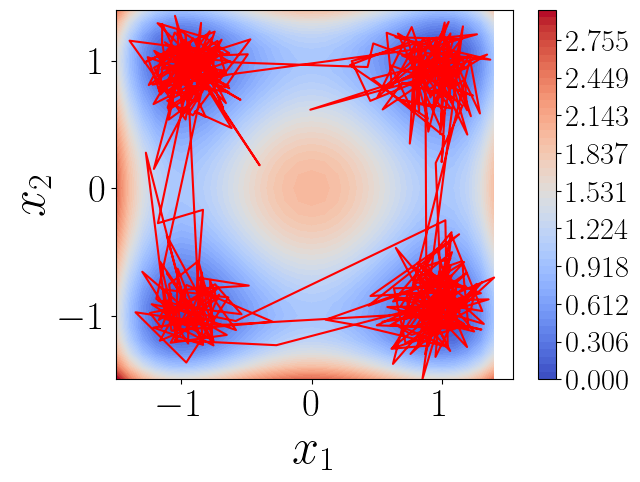

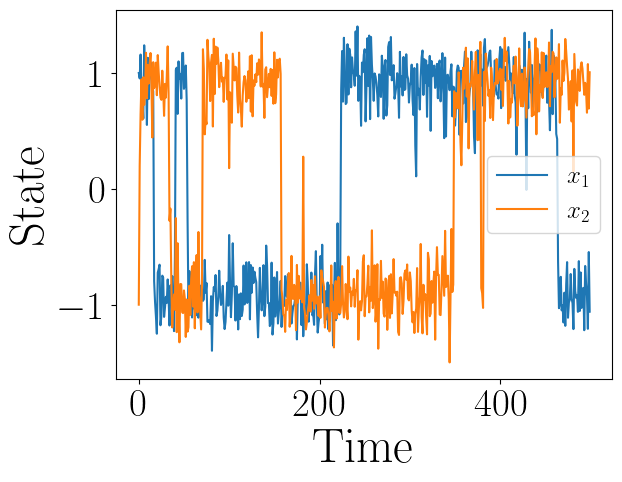

In [ ]:
# Plotting quadruple well from deeptime

system = deeptime.data.quadruple_well(n_steps=1000)
traj = system.trajectory(np.array([[1, -1]]), 500, seed=46)

xy = np.arange(-1.5, 1.5, 0.1)
coords = np.dstack(np.meshgrid(xy, xy)).reshape(-1, 2)
V = system.potential(coords).reshape((xy.shape[0], xy.shape[0]))

x = np.r_[traj[:, 0]]
y = np.r_[traj[:, 1]]


with utils.nice_2d_plot() as (fig, ax):
    cb = ax.contourf(xy, xy, V,
                 levels=np.linspace(0.0, 3.0, 50),
                 cmap='coolwarm')
    ax.plot(x, y, color='red')
    ax.set_xlabel('$x_1$', fontsize=35)
    ax.set_ylabel('$x_2$', fontsize=35)

    # Colorbar
    cbar = fig.colorbar(cb)
    cbar.ax.tick_params(labelsize=22)
   # plt.savefig('./figures/quadruplewell_potential.pdf', bbox_inches="tight", dpi=300)


with utils.nice_2d_plot() as (fig, ax):
    ax.plot(traj[:, 0], label='$x_1$')
    ax.plot(traj[:, 1], label='$x_2$')
    plt.legend(fontsize=18, loc='best')
    ax.set_xlabel('Time', fontsize=35)
    ax.set_ylabel('State', fontsize=35)
    #plt.savefig('./figures/quadruplewell_trajs.pdf', bbox_inches="tight", dpi=300)

## OU process example

In [6]:
### Data


evs = 5              # Number of dominant eigenvalues and eigenfunctions

# h = 1e-3             # Step size

# iters = 500          # Iterations in EM

# beta = 4.0816              # Inverse temperature
# dim = 2
# m = 5000              # Number of data points

# X = np.random.uniform(-2.0, 2.0, size=(dim, m))          # Data points in x       

# data = EulerMaruyama(x0=X, h=h, iters=iters)           # Calling Euler-Maruyama class 

# Y = data.sample(potential_name='double2d', beta=beta)                # Data points in y

#Y_one = data.sample(potential_name='double2d', beta=beta)
# X = Y_one[:, :-500:500]
# Y = Y_one[:, 500::500]

#sp.io.savemat('data/double2d_multishort_data.mat', {'X': X, 'Y': Y})

data = sp.io.loadmat('data/ou_data.mat') 
x = data['ou_data']
X = x[:, :-1]
Y = x[:, 1:]


exact_eigv = [np.exp(-0.5 * i) for i in range(5)]


def exact_eigf_ou(x, i):
    if i == 0:  # Exact eigenfunctions
        return np.ones(x.shape[1])
    if i == 1:
        return 2 * x
    if i == 2:
        return (4 * x**2 - 1) / np.sqrt(2)
    if i == 3:
        return (8 * x**3 - 6 * x) / np.sqrt(6)
    if i == 4:
        return (16 * x**4 - 24 * x**2 + 3) / np.sqrt(24)


(array([[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]], shape=(50, 50)),
 array([-1.47302328, -1.41479291, -1.35656254, -1.29833217, -1.2401018 ,
        -1.18187142, -1.12364105, -1.06541068, -1.00718031, -0.94894994,
        -0.89071957, -0.83248919, -0.77425882, -0.71602845, -0.65779808,
        -0.59956771, -0.54133733, -0.48310696, -0.42487659, -0.36664622,
        -0.30841585, -0.25018548, -0.1919551 , -0.13372473, -0.07549436,
        -0.01726399,  0.04096638,  0.09919676,  0.15742713,  0.2156575 ,
         0.27388787,  0.33211824,  0.39034861,  0.44857899,  0.50680936,
         0.56503973,  0.6232701 ,  0.68150047,  0.73973084,  0.79796122,
         0.85619159,  0.91442196,  0.97265233,  1.0308827 ,  1.08911308,
         1.14734345,  1.20557382,  1.26380419,  1.32203456,  1.38026493,
     

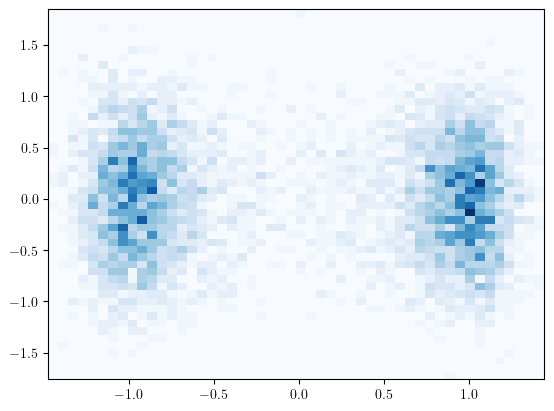

In [ ]:
plt.hist2d(Y[0, :], Y[1, :], bins=50, cmap='Blues')
plt.show()

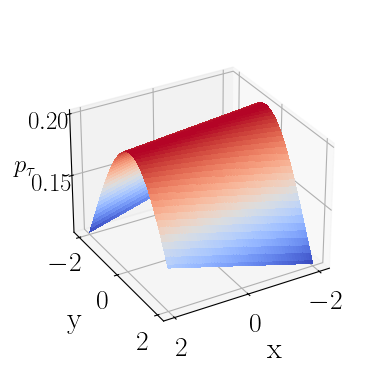

In [2]:
## plotting OU transition density function

def transition_density_ou(x, y, alpha, beta, tau):
    sigma2tau = (1/alpha*beta)*(1 - np.exp(-2*alpha * tau))
    fac = 1/np.sqrt(2* np.pi* sigma2tau)
    return fac*np.exp(-(y - x*np.exp(-alpha * tau))**2 / (2 * sigma2tau))

alpha = 1
beta = 4
tau = 2.0
 
x = np.linspace(-2, 2, 100)
y = np.linspace(-2, 2, 100)

xx, yy = np.meshgrid(x, y)

zz = transition_density_ou(xx, yy, alpha, beta, tau)

with utils.nice_3d_plot() as (fig, ax):
    ax.set_ylabel('y', size=22, labelpad=15)
    ax.set_xlabel('x', size=22, labelpad=15)
    ax.set_zlabel(r'$p_{\tau}$', size=18, labelpad=6)
    ax.zaxis.set_rotate_label(False)
   # ax.zaxis.label.set_rotation(0)
    ax.view_init(azim=60, elev=30)
    ax.set_box_aspect(None, zoom=0.8)
    ax.zaxis.set_ticks(np.array([-0.01, 0.0, 0.05, 0.1, 0.15, 0.2]))
    ax.zaxis.set_tick_params(labelsize=18)
    # ax.zaxis.labelpad=6
    surf = ax.plot_surface(xx, yy, zz, cmap=plt.cm.coolwarm, antialiased=False)
    #plt.savefig(f'./figures/ou_density_tau{tau}.pdf', bbox_inches='tight', dpi=300)

In [3]:
# define domain
bounds = np.array([[-2, 0]])
boxes = np.array([20])
Omega = domain.discretization(bounds, boxes)


## data for gEDMD

alpha = 1
beta = 4


psi = observables.monomials(4)

domain_eigf = np.linspace(-2, 2, 500).reshape(1, -1)
evs = 5
PsiC = psi(domain_eigf) 


In [18]:

# #%% EDMD for Perron-Frobenius operator
# _, dp, Vp = algorithms.edmd(X, Y, psi, operator='P', evs=evs)
# eigf_p = np.real(Vp.T @ PsiC)

# with utils.nice_2d_plot() as (fig2, ax2):
#     for i in range(evs):
#         ax2.scatter(Omega.midpointGrid(), eigf_p[i, :]/np.amax(np.abs(eigf_p[i, :])))
#         #plt.savefig('./figures/edmd_ou_pf_eigf.pdf', bbox_inches="tight", dpi=300)

In [8]:
## EDMD for Koopman operator and generator

def b(x):
    return -alpha*x

def sigma(x):
   return np.sqrt(2/beta)*np.ones((1, 1, x.shape[1]))

X = Omega.rand(10000)
Y1 = b(X)
Z1 = sigma(X)


# gEDMD for Koopman generator
K1, d1, V1 = algorithms.gedmd(X, Y1, Z1, psi, evs=evs, operator='K')
eigf_kg = V1.T @ PsiC

  
# _, d1, V1 = algorithms.edmd(X, Y, psi, operator='K', evs=evs)
# eigf_k = np.real(V1.T @ PsiC)



true_eigf_ou = np.zeros((evs, PsiC.shape[1]))
for i in range(evs):
    true_eigf_ou[i, :] = exact_eigf_ou(domain_eigf, i)

In [ ]:
# C_xx = psi(X) @ psi(X).T
# C_xy = psi(X) @ psi(Y).T
# rank_cxx = np.linalg.matrix_rank(C_xx)
# rank_cxy = np.linalg.matrix_rank(C_xy)
# cond_cxx = np.linalg.cond(C_xx)
# print(f"Condition number of C_xx: {cond_cxx}")
# print(f"Rank of C_xx: {rank_cxx}")
# print(f"Rank of C_xy: {rank_cxy}")

Condition number of C_xx: 317084267.22710943
Rank of C_xx: 13
Rank of C_xy: 13


In [9]:

for i in range(evs):
    V_exact = true_eigf_ou[i, :]
    V_1 = eigf_kg[i, :]
    V_2 = -eigf_kg[i, :]
    e1 = np.linalg.norm(V_exact - V_1)
    e2 = np.linalg.norm(V_exact - V_2)
    if e1 > e2:
        eigf_kg[i, :] = -eigf_kg[i, :]

cols = ['red', 'blue', 'black', 'green']

In [9]:
eigf_k.shape

(5, 500)

/tmp/ipykernel_13293/1813583044.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=18, loc='best', markerscale=5)


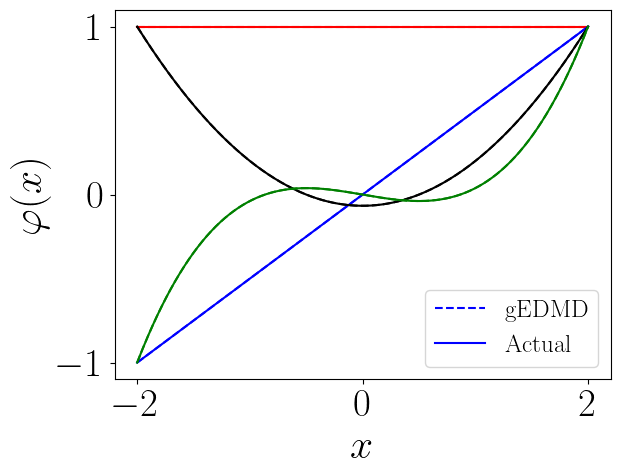

In [ ]:


with utils.nice_2d_plot(xlabel=r'$x$', ylabel=r'$\varphi(x)$') as (fig3, ax3):
    for i in range(evs-1):
        ax3.plot(domain_eigf.reshape(-1), (eigf_kg[i, :]/np.amax(np.abs(eigf_kg[i, :]))), linestyle='--', color=cols[i],  label='gEDMD' if i == 1 else None)
        ax3.plot(domain_eigf.reshape(-1), (true_eigf_ou[i, :]/np.amax(np.abs(true_eigf_ou[i, :]))), linestyle='-', color=cols[i], label='Actual' if i == 1 else None)
        plt.legend(fontsize=18, loc='best', markerscale=5)
        #plt.savefig('./figures/gedmd_ou_eigfk_4monom.pdf', bbox_inches="tight", dpi=300)

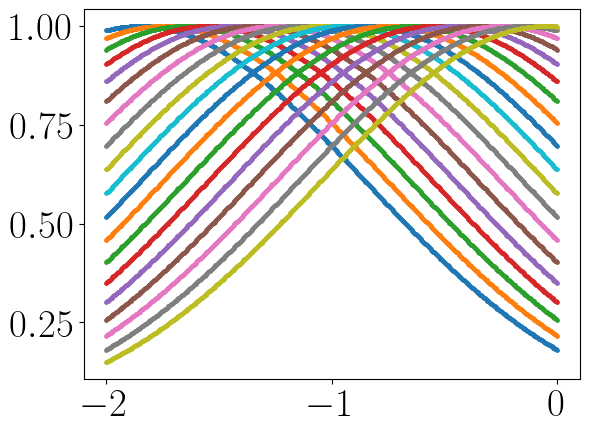

In [17]:
with utils.nice_2d_plot() as (fig4, ax4):
    for i in range(1, 20):
        ax4.scatter(domain_eigf, (PsiC[i, :]), marker='o', s=6)
        
        #plt.legend(fontsize=18, loc='best')
        #plt.savefig('./figures/edmd_ou_leftgaussiansbasis.pdf', bbox_inches="tight", dpi=300)

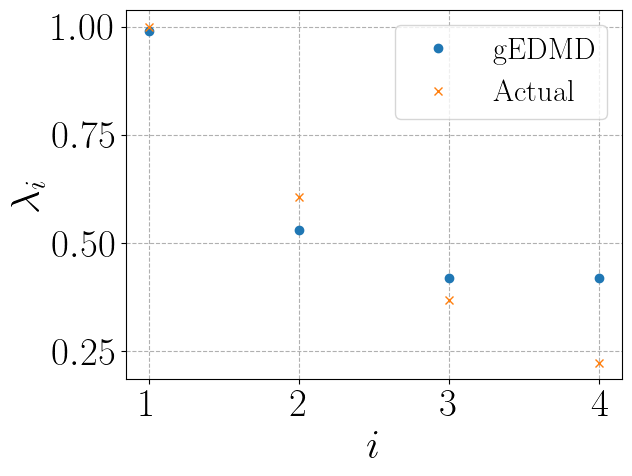

In [ ]:
with utils.nice_2d_plot() as (fig4, ax4):
    
    ax4.plot(np.arange(1, 5, 1), d1[:4], 'o', label='EDMD')
    #ax4.plot(np.arange(1, 5, 1), -np.arange(4), 'x', label='Actual')
    ax4.plot(np.arange(1, 5, 1), exact_eigv[:4], 'x', label='Actual')
    plt.legend(fontsize=22, loc='best')
    plt.grid(which="minor", linestyle=":")
    plt.grid(which="major", linestyle="--")
    plt.xlabel(r"$i$", fontsize=30)
    plt.ylabel(r"$\lambda_i$", fontsize=30)
    #plt.savefig('./figures/gedmd_ou_eigvk_4monom.pdf', bbox_inches="tight", dpi=300)

In [46]:
dk

array([1.        +0.j, 0.61305515+0.j, 0.36887373+0.j, 0.23088058+0.j,
       0.12390588+0.j])

### Moving 5 wells CCA example

In [ ]:
## load saved data

# data = sp.io.loadmat('data/moving5well.mat')

# X = data['X']
# Y = data['Y']

X = np.random.uniform(-2.0, 2.0, size=(2, 500))          # Data points in x
Y = 0.5 * X + 5.0

Omega = domain.discretization(bounds=np.array([[-2, 2], [-2, 2]]), boxes=np.array([10, 10]))

psi = observables.monomials(3)

PsiX = psi(X)
PsiY = psi(Y)

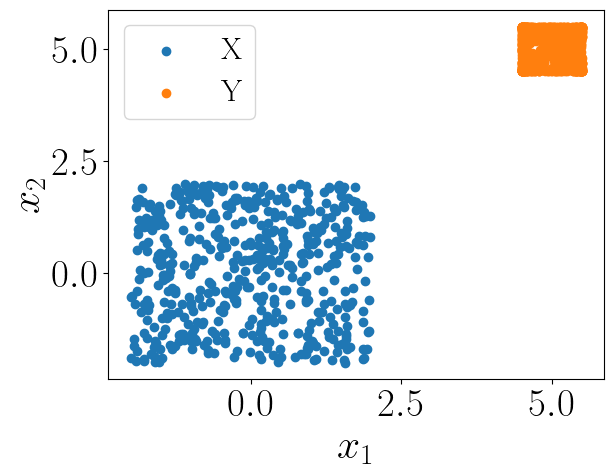

In [3]:
with utils.nice_2d_plot(xlabel=r'$x_1$', ylabel=r'$x_2$') as (fig4, ax4):
        
    plt.scatter(X[0, :], X[1, :], label='X')
    plt.scatter(Y[0, :], Y[1, :], label='Y')
    plt.legend(fontsize=22, loc='best')
   
    #plt.savefig('./figures/cca_data.pdf', bbox_inches="tight", dpi=300)


In [66]:
# plt.hist2d(Y[0, :], Y[1, :], bins=100)
# plt.show()

/home/s2421480/miniconda3/envs/pypr-25/lib/python3.12/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/s2421480/miniconda3/envs/pypr-25/lib/python3.12/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


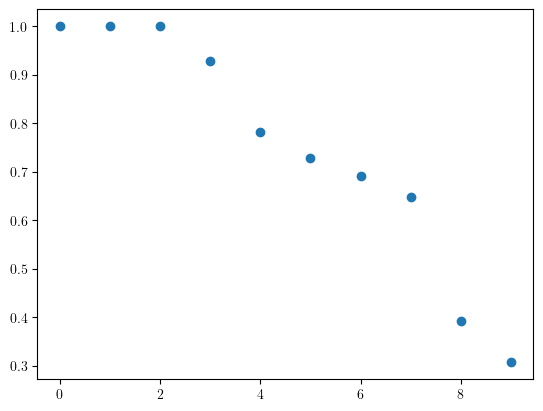

In [4]:
sigma = 1
#k = kernels.gaussianKernel(sigma)

#%% apply kernel CCA to detect coherent sets
evs = 10  # number of eigenfunctions to be computed
d, V = algorithms.cca(X, Y, psi, evs)

#%% plot eigenvalues
plt.figure()
plt.plot(d, 'o')
plt.show()

eigfx = V.T @ PsiX
Vy = np.linalg.pinv(PsiX @ PsiY.T) @ np.diag(d) @ (PsiX @ PsiX.T) @ V
eigfy = Vy.T @ PsiY

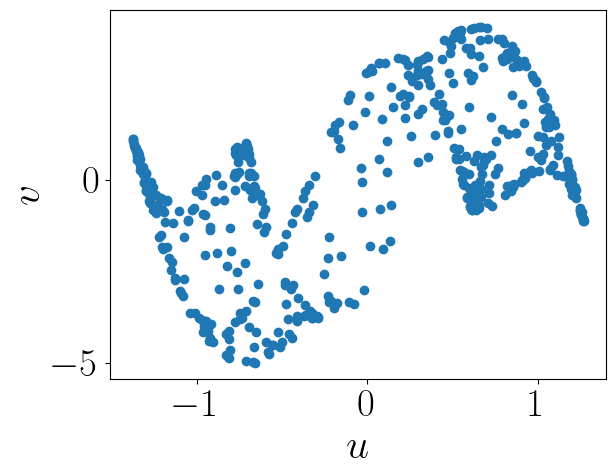

In [7]:
with utils.nice_2d_plot(xlabel=r'$u$', ylabel=r'$v$') as (fig4, ax4):    
    plt.scatter(eigfx[2, :], eigfy[2, :])
    #plt.legend(fontsize=22, loc='best')
    #plt.savefig('./figures/cca_relation.pdf', bbox_inches="tight", dpi=300)



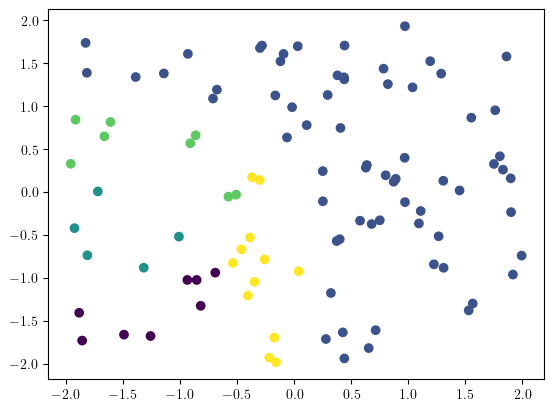

In [9]:
#%% k-means of eigenvectors
c, l = sp.cluster.vq.kmeans2(np.real(PsiX[0:5, :]).T, 5, iter=1000)
fig = plt.figure()
plt.scatter(X[0, :], X[1, :], c=l)
plt.show()

In [19]:
PsiX.shape

(25, 1000)